In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [39]:
ca = pd.read_csv('cust_activity.csv')
ca.head()
cb = pd.read_csv('cust_bio.csv')
cb.head()
cs = pd.read_csv('cust_sub.csv')
cs.head()
orders= pd.read_csv('orders.csv')
orders.head()
sp = pd.read_csv('sp.csv')
sp.head()

,Plan_Var_ID,Plan_ID,Plan_name,Price,Duration
0,P1_1Y,P1,Silver,1200.0,1 Year
1,P1_6M,P1,Silver,720.0,6 Months
2,P2_1Y,P2,Gold,2400.0,1 Year
3,P2_6M,P2,Gold,1440.0,6 Months
4,P3_1Y,P3,Diamond,4800.0,1 Year


In [40]:
ca.shape

(7500, 3)

In [41]:
cb.shape

(478, 3)

In [42]:
cs.shape

(51, 3)

In [43]:
orders.shape

(127, 4)

In [44]:
sp.shape

(6, 5)

In [45]:
print(ca.columns)
print(cb.columns)
print(cs.columns)
print(orders.columns)
print(sp.columns)

Index(['Cust_ID', 'Activity', 'Date'], dtype='object')
Index(['Cust_ID', 'City', 'Age'], dtype='object')
Index(['Cust_ID', 'Plan_Var_ID', 'Purchase_Date'], dtype='object')
Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='object')
Index(['Plan_Var_ID', 'Plan_ID', 'Plan_name', 'Price', 'Duration'], dtype='object')


#### Prelimnary Analysis - Seaborn + plotly
<pre>
1) Check null values and duplicates in each df.
2) Find Count of Customers from each city and represent it on bar chart.
3) Find Range Age wise count of cutsomers, represent it on pie chart.
4) Find Count of each activity, represent it on bar chart
5) Find order month wise total amount. Represent it on line chart.
6) Find Sub_Plan wise total revenue generated. Represent it on bar chart.
7) City wise find total amount
8) Find count of each payment mode, represent it on donut chart
9) Represent Payment mode wise sum of amount on a strip plot

</pre>
#### Objective - Funnel Analysis
<pre>
1) Generate the Entire Funnel. Represent 4 columns
- Funnel_Stage, Count_of_Cust, Percenatge_Conversion

2) Find Customer wise count of days to transition from one stage of funnel to the next stage

3) Find Avg_Days to transition from one Funnel stage to the next stage.

4) Create function to analyse Funnel based on City.

</pre>


In [46]:
# 1) Check null values and duplicates in each df.print(ca.columns)
print(cb.isnull().sum().head())
print(cs.isnull().sum().head())
print(orders.isnull().sum().head())
print(sp.isnull().sum().head())


Cust_ID    0
City       0
Age        0
dtype: int64
Cust_ID          0
Plan_Var_ID      0
Purchase_Date    0
dtype: int64
Order_id        0
Cust_ID         0
Amount          0
Payment_mode    0
dtype: int64
Plan_Var_ID    0
Plan_ID        0
Plan_name      0
Price          0
Duration       0
dtype: int64


In [47]:
for i in [ca,cb,cs,orders,sp]:
    print(i.duplicated().sum())

0
0
0
0
0


In [48]:
def check_dup(data):
    dup = data.duplicated().sum()
    if dup>0:
        print(dup)
    else:
        print('no duplicates')

In [49]:
check_dup(ca)

no duplicates


In [50]:
import plotly.express as px

In [51]:
# 2) Find Count of Customers from each city and represent it on bar chart.
q2 = cb['City'].value_counts().reset_index()
q2

,City,count
0,Chennai,109
1,Delhi,106
2,Kolkata,94
3,Noida,92
4,Mumbai,77


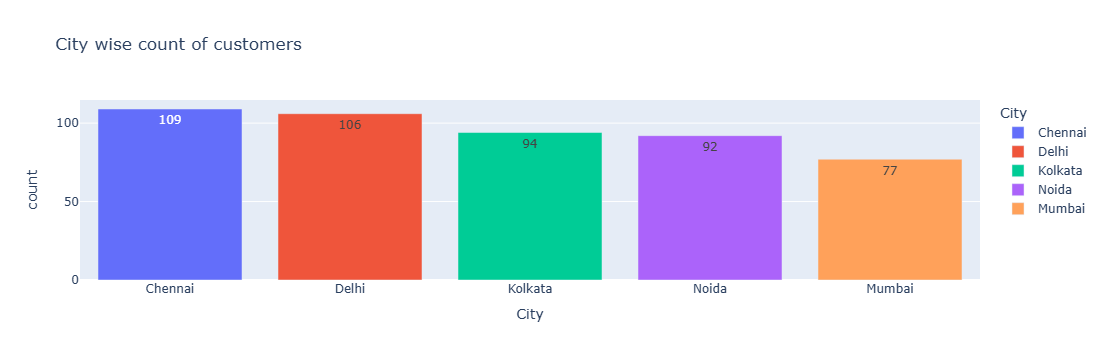

In [52]:
fig = px.bar(data_frame = q2, x='City',y='count',title='City wise count of customers',text='count',color='City')
fig.show()

In [53]:
# 3) Find Range Age wise count of cutsomers, represent it on pie chart.
# q3= cb['Age'].value_counts().reset_index().head()
# q3
cb['Age_Range'] = pd.cut(cb['Age'],bins = [19,24,29,34,39])
cb['Age_Range'] = cb['Age_Range'].astype(str)

In [54]:
q3 = cb['Age_Range'].value_counts().reset_index()
q3

,Age_Range,count
0,"(19, 24]",137
1,"(29, 34]",130
2,"(24, 29]",120
3,"(34, 39]",91


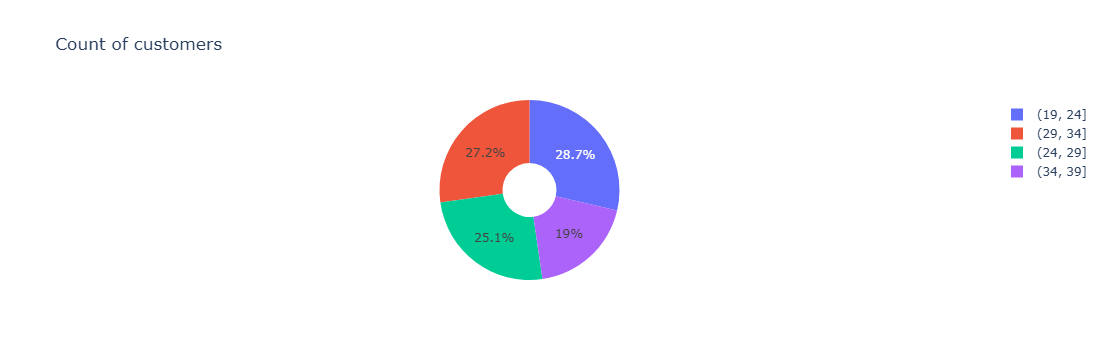

In [55]:
fig = px.pie(data_frame = q3,names = 'Age_Range',values='count',title='Count of customers',hole=0.3)
fig.show()

In [56]:
# 4) Find Count of each activity, represent it on bar chart
q4 = ca['Activity'].value_counts().reset_index()
q4

,Activity,count
0,Browse,6548
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


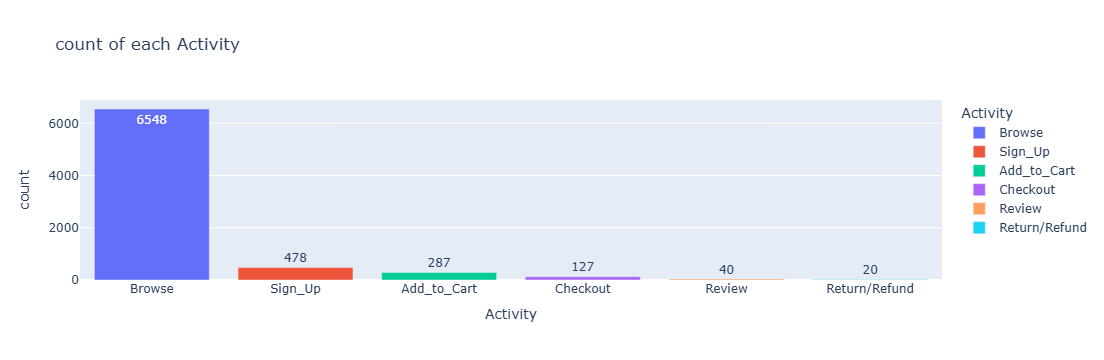

In [57]:
fig = px.bar(data_frame = q4, x='Activity',y='count',title='count of each Activity',text='count',color='Activity')
fig.show()

In [58]:
# 5) Find order month wise total amount. Represent it on line chart.
ca['Date'] = pd.to_datetime(ca['Date'])
ca['Month'] = ca['Date'].dt.month

In [59]:
ca.dtypes

Cust_ID             object
Activity            object
Date        datetime64[ns]
Month                int32
dtype: object

In [60]:
ca_checkout = ca[ca['Activity']=='Checkout']
print(ca_checkout.shape)
print(orders.shape)

(127, 4)
(127, 4)


In [61]:
ca_orders = pd.merge(orders,ca_checkout, on ='Cust_ID',how='inner')
ca_orders.head()

,Order_id,Cust_ID,Amount,Payment_mode,Activity,Date,Month
0,ORD_71,CUS_545,2123.19,UPI,Checkout,2024-04-26,4
1,ORD_72,CUS_622,2788.02,Net Banking,Checkout,2024-02-01,2
2,ORD_73,CUS_418,3071.63,Credit_Card,Checkout,2024-07-22,7
3,ORD_74,CUS_360,5736.31,COD,Checkout,2025-05-24,5
4,ORD_75,CUS_714,1592.53,Debit Card,Checkout,2024-06-19,6


In [62]:
q5= ca_orders.groupby(ca_orders['Month'])['Amount'].sum().reset_index()
q5.head()

,Month,Amount
0,1,27022.20
1,2,70477.42
2,3,74777.59
3,4,88080.66
4,5,60200.46


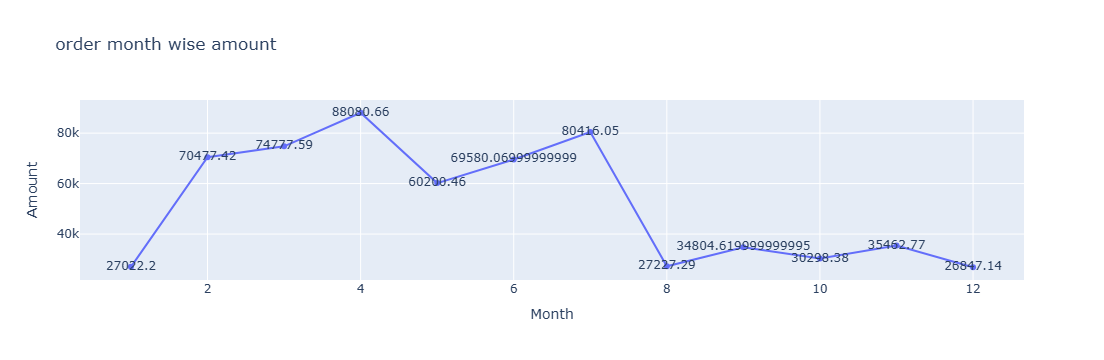

In [63]:
fig = px.line(data_frame = q5, x='Month',y='Amount',title='order month wise amount',text='Amount')
fig.show()

In [64]:
# 6) Find Sub_Plan wise total revenue generated. Represent it on bar chart.
cs_sp = pd.merge(cs,sp,on='Plan_Var_ID',how='inner')
cs_sp.head()

,Cust_ID,Plan_Var_ID,Purchase_Date,Plan_ID,Plan_name,Price,Duration
0,CUS_626,P1_1Y,2025-05-15,P1,Silver,1200.0,1 Year
1,CUS_723,P1_1Y,2024-07-23,P1,Silver,1200.0,1 Year
2,CUS_575,P1_1Y,2024-11-14,P1,Silver,1200.0,1 Year
3,CUS_232,P2_6M,2025-04-19,P2,Gold,1440.0,6 Months
4,CUS_346,P2_1Y,2024-01-31,P2,Gold,2400.0,1 Year


In [65]:
q6 = cs_sp.groupby(['Plan_Var_ID'])['Price'].sum().reset_index()
q6

,Plan_Var_ID,Price
0,P1_1Y,16800.0
1,P1_6M,5040.0
2,P2_1Y,24000.0
3,P2_6M,7200.0
4,P3_1Y,28800.0
5,P3_6M,25920.0


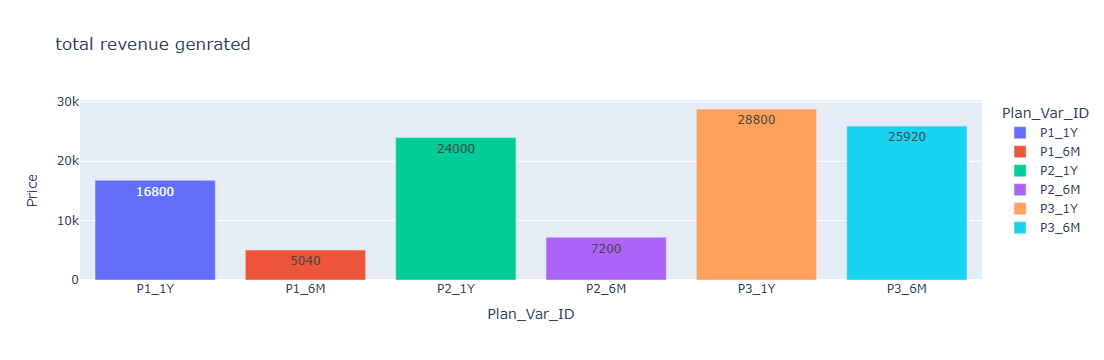

In [66]:
fig = px.bar(data_frame =q6,x='Plan_Var_ID',y='Price',title='total revenue genrated',text='Price',color='Plan_Var_ID')
fig.show()

In [67]:
# 7) City wise find total amount
c_amt = pd.merge(orders,cb,on ='Cust_ID',how='inner')
c_amt

,Order_id,Cust_ID,Amount,Payment_mode,City,Age,Age_Range
0,ORD_71,CUS_545,2123.19,UPI,Delhi,25,"(24, 29]"
1,ORD_72,CUS_622,2788.02,Net Banking,Kolkata,27,"(24, 29]"
2,ORD_73,CUS_418,3071.63,Credit_Card,Noida,23,"(19, 24]"
3,ORD_74,CUS_360,5736.31,COD,Noida,25,"(24, 29]"
4,ORD_75,CUS_714,1592.53,Debit Card,Mumbai,29,"(24, 29]"
...,...,...,...,...,...,...,...
122,ORD_193,CUS_512,5509.80,Credit_Card,Kolkata,31,"(29, 34]"
123,ORD_194,CUS_292,6409.17,Credit_Card,Noida,36,"(34, 39]"
124,ORD_195,CUS_372,6715.57,Credit_Card,Delhi,27,"(24, 29]"
125,ORD_196,CUS_795,4226.04,COD,Chennai,32,"(29, 34]"


In [68]:
q7= c_amt.groupby(c_amt['City'])['Amount'].sum().reset_index()
q7.head()

,City,Amount
0,Chennai,96763.72
1,Delhi,147176.17
2,Kolkata,102185.83
3,Mumbai,120515.98
4,Noida,158552.95


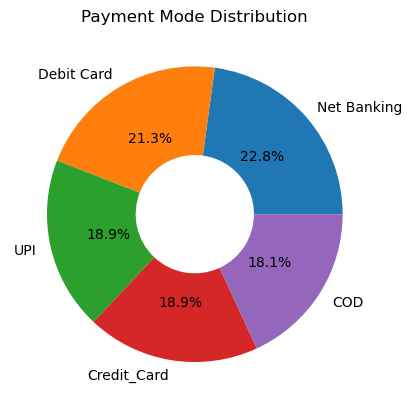

In [69]:
# 8) Find count of each payment mode, represent it on donut chart
q7  = orders['Payment_mode'].value_counts()
q7.head()
plt.pie(q7.values,labels = q7.index,autopct='%1.1f%%',wedgeprops={'width': 0.6})
plt.title('Payment Mode Distribution')
plt.show()

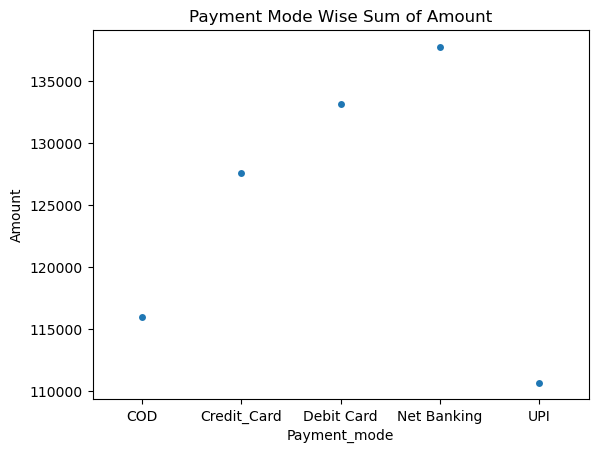

In [70]:
# 9) Represent Payment mode wise sum of amount on a strip plot
q8 = orders.groupby('Payment_mode')['Amount'].sum().reset_index()

sns.stripplot(data=q8,x='Payment_mode', y='Amount' )
plt.title('Payment Mode Wise Sum of Amount')
plt.show()

1) Generate the Entire Funnel. Represent 4 columns
- Funnel_Stage, Count_of_Cust, Percenatge_Conversion

In [71]:
ca.head()

,Cust_ID,Activity,Date,Month
0,CUS_121,Sign_Up,2024-04-24,4
1,CUS_121,Browse,2024-04-27,4
2,CUS_121,Add_to_Cart,2024-04-27,4
3,CUS_121,Browse,2024-04-29,4
4,CUS_121,Browse,2024-04-30,4


In [72]:
ca['Activity'].value_counts()

Activity
Browse           6548
Sign_Up           478
Add_to_Cart       287
Checkout          127
Review             40
Return/Refund      20
Name: count, dtype: int64

In [73]:
w1 = ca.groupby(['Cust_ID','Activity'])['Activity'].count().reset_index(name='Count')
w1.head()

,Cust_ID,Activity,Count
0,CUS_121,Add_to_Cart,1
1,CUS_121,Browse,8
2,CUS_121,Checkout,1
3,CUS_121,Sign_Up,1
4,CUS_122,Browse,10


In [74]:
funnel = w1['Activity'].value_counts().reset_index()
funnel

,Activity,count
0,Browse,681
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


In [75]:
funnel['Prev_Count'] = np.where(funnel['Activity']=='Return/Refund',funnel['count'].shift(2),
                                funnel['count'].shift(1))
funnel  

,Activity,count,Prev_Count
0,Browse,681,NaN
1,Sign_Up,478,681.0
2,Add_to_Cart,287,478.0
3,Checkout,127,287.0
4,Review,40,127.0
5,Return/Refund,20,127.0


In [76]:
funnel['Per_Conversion']= round((funnel['count']/funnel['Prev_Count'])*100,2)
funnel.fillna(0,inplace=True)
funnel

,Activity,count,Prev_Count,Per_Conversion
0,Browse,681,0.0,0.00
1,Sign_Up,478,681.0,70.19
2,Add_to_Cart,287,478.0,60.04
3,Checkout,127,287.0,44.25
4,Review,40,127.0,31.50
5,Return/Refund,20,127.0,15.75


In [77]:
funnel['Per_Conversion'] = funnel['Per_Conversion'].apply(lambda x: str(x) +'%')
funnel

,Activity,count,Prev_Count,Per_Conversion
0,Browse,681,0.0,0.0%
1,Sign_Up,478,681.0,70.19%
2,Add_to_Cart,287,478.0,60.04%
3,Checkout,127,287.0,44.25%
4,Review,40,127.0,31.5%
5,Return/Refund,20,127.0,15.75%


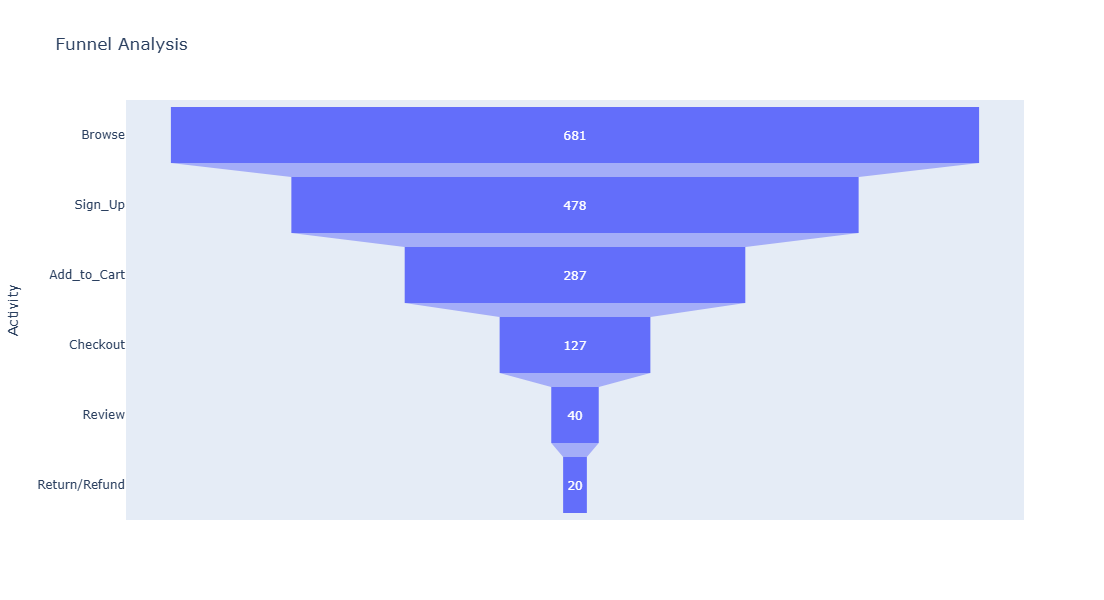

In [78]:
fig = px.funnel(data_frame=funnel,x='count',y='Activity',
                title = 'Funnel Analysis',height=600,hover_data='Per_Conversion')
fig.show()

#### 2) Find Customer wise count of days to transition from one stage of funnel to the next stage


In [79]:
pt1 = pd.pivot_table(data=ca,index=['Cust_ID'],columns=['Activity'],
                     values='Date',aggfunc='min')
pt1.head(15)

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up
Cust_ID,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15
CUS_126,NaT,2024-02-28,NaT,NaT,NaT,2024-02-27
CUS_127,2024-05-28,2024-05-28,2024-06-16,NaT,NaT,2024-05-26
CUS_128,NaT,2024-06-12,NaT,NaT,NaT,NaT
CUS_129,2025-03-22,2025-03-22,2025-04-02,NaT,NaT,2025-03-21


In [80]:
#DD
pt1['DD_Browse_2_Signup'] = abs((pt1['Browse'] - pt1['Sign_Up']).dt.days)
pt1['DD_Signup_2_Add2Cart'] = (pt1['Add_to_Cart'] - pt1['Sign_Up']).dt.days
pt1['DD_Add2Cart_2_Checkout'] = (pt1['Checkout'] - pt1['Add_to_Cart']).dt.days
pt1['DD_Checkout_2_Review'] = (pt1['Review'] - pt1['Checkout']).dt.days
pt1['DD_Checkout_2_Return/Refund'] = (pt1['Return/Refund'] - pt1['Checkout']).dt.days
pt1.head()

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up,DD_Browse_2_Signup,DD_Signup_2_Add2Cart,DD_Add2Cart_2_Checkout,DD_Checkout_2_Review,DD_Checkout_2_Return/Refund
Cust_ID,,,,,,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24,3.0,3.0,8.0,NaN,NaN
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05,1.0,1.0,NaN,NaN,NaN
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15,2.0,NaN,NaN,NaN,NaN


In [81]:
pt2 = pt1.iloc[:,-5:]
pt2.head()

Activity,DD_Browse_2_Signup,DD_Signup_2_Add2Cart,DD_Add2Cart_2_Checkout,DD_Checkout_2_Review,DD_Checkout_2_Return/Refund
Cust_ID,,,,,
CUS_121,3.0,3.0,8.0,NaN,NaN
CUS_122,NaN,NaN,NaN,NaN,NaN
CUS_123,NaN,NaN,NaN,NaN,NaN
CUS_124,1.0,1.0,NaN,NaN,NaN
CUS_125,2.0,NaN,NaN,NaN,NaN


In [82]:
orders.columns

Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='object')

In [83]:
pt2.mean()

Activity
DD_Browse_2_Signup              2.516736
DD_Signup_2_Add2Cart            2.512195
DD_Add2Cart_2_Checkout         14.425197
DD_Checkout_2_Review            2.625000
DD_Checkout_2_Return/Refund     3.400000
dtype: float64

In [87]:
##3) 
tran_days = pt2.mean()

In [88]:
avg_days_to_trans = [0] + list(tran_days.values)
print(avg_days_to_trans)

[0, np.float64(2.51673640167364), np.float64(2.5121951219512195), np.float64(14.4251968503937), np.float64(2.625), np.float64(3.4)]


In [89]:
funnel['Avg_Days_2Tran'] = avg_days_to_trans
funnel['Avg_Days_2Tran'] = funnel['Avg_Days_2Tran'].apply(lambda x : round(x,2))
funnel

,Activity,count,Prev_Count,Per_Conversion,Avg_Days_2Tran
0,Browse,681,0.0,0.0%,0.00
1,Sign_Up,478,681.0,70.19%,2.52
2,Add_to_Cart,287,478.0,60.04%,2.51
3,Checkout,127,287.0,44.25%,14.43
4,Review,40,127.0,31.5%,2.62
5,Return/Refund,20,127.0,15.75%,3.40


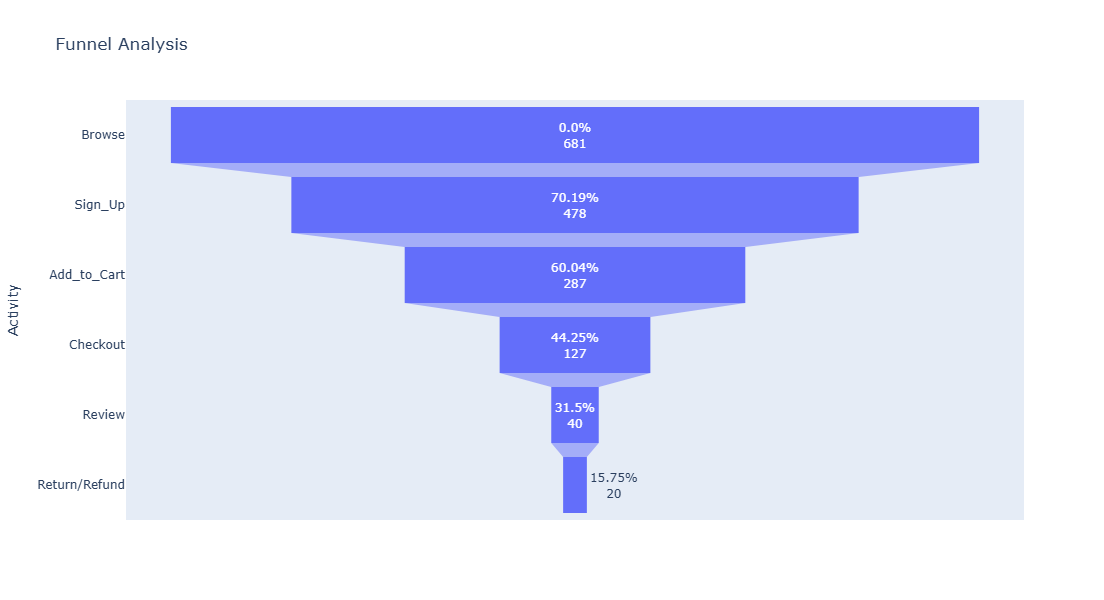

In [90]:
fig1 = px.funnel(data_frame=funnel,y='Activity',x='count', text='Per_Conversion',
                title = 'Funnel Analysis',height=600,hover_data='Avg_Days_2Tran')
fig1.show()

In [91]:
#4) Create function to analyse Funnel based on City.

cb.head()

,Cust_ID,City,Age,Age_Range
0,CUS_121,Noida,30,"(29, 34]"
1,CUS_124,Kolkata,20,"(19, 24]"
2,CUS_125,Kolkata,24,"(19, 24]"
3,CUS_126,Chennai,24,"(19, 24]"
4,CUS_127,Delhi,24,"(19, 24]"


In [92]:
def city_wise_funnel(city_name):
    city_df = cb[cb['City'] == city_name]
    return city_df

In [93]:
city_wise_funnel('Delhi')

,Cust_ID,City,Age,Age_Range
4,CUS_127,Delhi,24,"(19, 24]"
24,CUS_152,Delhi,31,"(29, 34]"
28,CUS_159,Delhi,31,"(29, 34]"
32,CUS_163,Delhi,22,"(19, 24]"
36,CUS_168,Delhi,23,"(19, 24]"
...,...,...,...,...
454,CUS_771,Delhi,26,"(24, 29]"
461,CUS_779,Delhi,27,"(24, 29]"
471,CUS_790,Delhi,29,"(24, 29]"
474,CUS_794,Delhi,30,"(29, 34]"


#### window function
1) lead,lad - shift
2) rank,dense_rank,row_number - rank

In [ ]:
demo = pd.DataFrame({'City':['Delhi']*5 + ['Noida']*5 + ['Pune']*5,
                     'Sales':[5000,6000,6000,7500,9000,3500,4200,5400,8700,8700,11500,14500,18000,18000,18000],
                     'Year': [2015,2016,2017,2018,2019]*3})
demo


In [ ]:
demo1 = demo.copy()

In [ ]:
noida = demo.query("City=='Noida'")
noida

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
noida['Rank_min'] = noida['Sales'].rank(ascending = False,method='min')
noida['Rank_max'] = noida['Sales'].rank(ascending = False,method='max')
noida['Rank_avg'] = noida['Sales'].rank(ascending = False,method='average')
noida['Rank_first'] = noida['Sales'].rank(ascending = False,method='first')
noida['Rank_dense'] = noida['Sales'].rank(ascending = False,method='dense')
noida

#### Find city wise top 3 salse? - demo1
select * from (SELECT City, Sales,row_number() OVER (PARTITION BY City ORDER BY Sales DESC) RN from demo1)dt where RN <=3;


In [ ]:
demo2 = demo1.copy()

In [ ]:
demo1['Rank'] = demo1.groupby('City')['Sales'].rank(ascending=False,method='dense')
demo1


In [ ]:
top3 = demo1[demo1['Rank']<=3]
top3

#### Find City and Sales where Sales is more than Avg Sales for that City?
select d2.city,d2.Sales
from demo2 d2
where d2.Sales > avg(Sales) from demo2 d1 where d1.city = d2.city); -- Sql

In [ ]:
# demo2

In [ ]:
w1  = demo2.groupby('City')['Sales'].mean().reset_index()
w1.columns = ['City','Avg_Sales']
w1

In [ ]:
w2 = pd.merge(demo2,w1,on='City')
res = w2[w2['Sales']> w2['Avg_Sales']]
res

In [ ]:
import sys
!{sys.executable} -m pip install folium --user

In [ ]:
import sys
!{sys.executable} -m pip install plotly --user

In [ ]:
import plotly.express as px